In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("Cleaned_Student_Performance.csv")

In [4]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,Total Marks,Percentage
0,Female,Group B,bachelor's degree,Standard,NaN,72,72,74,218,72.666667
1,Female,Group C,some college,Standard,Completed,69,90,88,247,82.333333
2,Female,Group B,master's degree,Standard,NaN,90,95,93,278,92.666667
3,Male,Group A,associate's degree,Free/Reduced,NaN,47,57,44,148,49.333333
4,Male,Group C,some college,Standard,NaN,76,78,75,229,76.333333


In [5]:
df.tail()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,Total Marks,Percentage
995,Female,Group E,master's degree,Standard,Completed,88,99,95,282,94.000000
996,Male,Group C,high school,Free/Reduced,NaN,62,55,55,172,57.333333
997,Female,Group C,high school,Free/Reduced,Completed,59,71,65,195,65.000000
998,Female,Group D,some college,Standard,Completed,68,78,77,223,74.333333
999,Female,Group D,some college,Free/Reduced,NaN,77,86,86,249,83.000000


In [6]:
df.shape

(1000, 10)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   gender                       1000 non-null   str    
 1   race/ethnicity               1000 non-null   str    
 2   parental level of education  1000 non-null   str    
 3   lunch                        1000 non-null   str    
 4   test preparation course      358 non-null    str    
 5   math score                   1000 non-null   int64  
 6   reading score                1000 non-null   int64  
 7   writing score                1000 non-null   int64  
 8   Total Marks                  1000 non-null   int64  
 9   Percentage                   1000 non-null   float64
dtypes: float64(1), int64(4), str(5)
memory usage: 78.3 KB


In [8]:
df.describe()

,math score,reading score,writing score,Total Marks,Percentage
count,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000,203.312000,67.770667
std,15.16308,14.600192,15.195657,42.771978,14.257326
min,0.00000,17.000000,10.000000,27.000000,9.000000
25%,57.00000,59.000000,57.750000,175.000000,58.333333
50%,66.00000,70.000000,69.000000,205.000000,68.333333
75%,77.00000,79.000000,79.000000,233.000000,77.666667
max,100.00000,100.000000,100.000000,300.000000,100.000000


In [9]:
df.groupby("parental level of education")[["math score", "reading score", "writing score"]].mean()

,math score,reading score,writing score
parental level of education,,,
associate's degree,67.882883,70.927928,69.896396
bachelor's degree,69.389831,73.000000,73.381356
high school,62.137755,64.704082,62.448980
master's degree,69.745763,75.372881,75.677966
some college,67.128319,69.460177,68.840708
some high school,63.497207,66.938547,64.888268


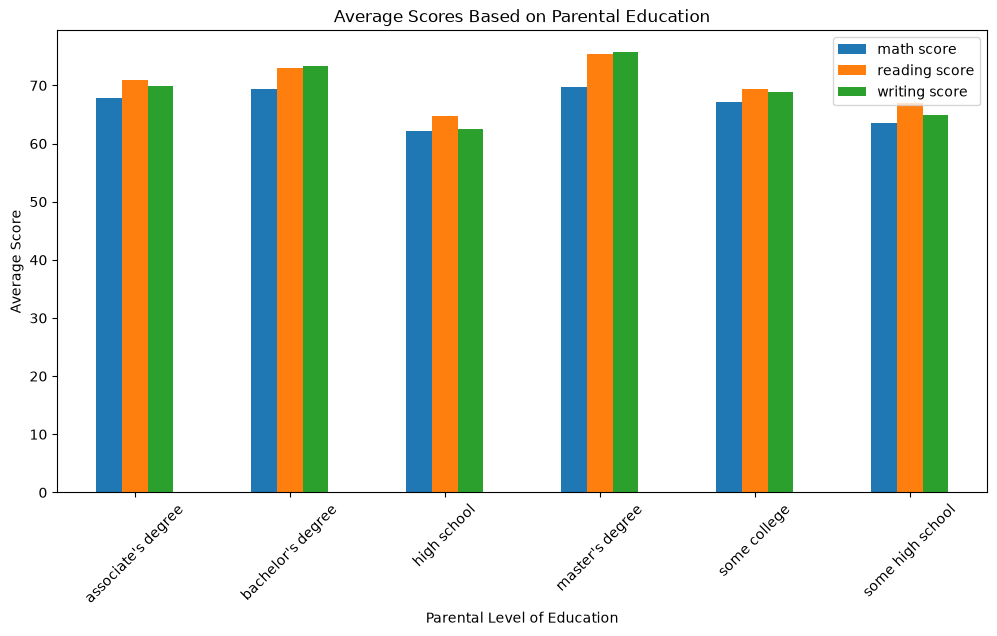

In [10]:
parental_avg = df.groupby("parental level of education")[["math score", "reading score", "writing score"]].mean()

parental_avg.plot(kind="bar", figsize=(12, 6))

plt.title("Average Scores Based on Parental Education")
plt.xlabel("Parental Level of Education")
plt.ylabel("Average Score")
plt.xticks(rotation=45)
plt.legend()
plt.show()

In [11]:
df.groupby("lunch")[["math score", "reading score", "writing score"]].mean()

,math score,reading score,writing score
lunch,,,
Free/Reduced,58.921127,64.653521,63.022535
Standard,70.034109,71.654264,70.823256


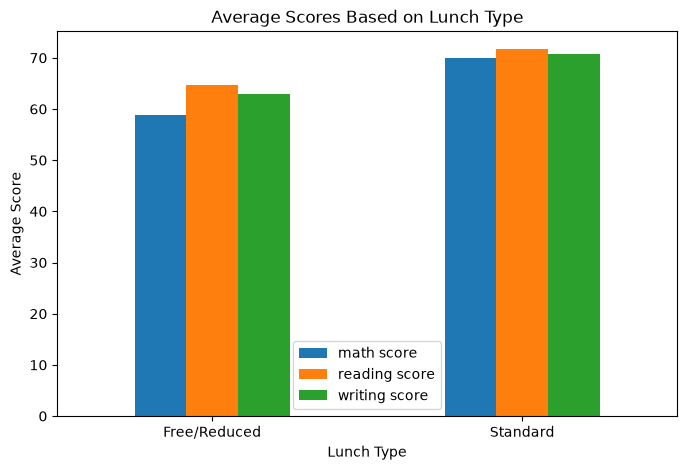

In [12]:
lunch_avg = df.groupby("lunch")[["math score", "reading score", "writing score"]].mean()

lunch_avg.plot(kind="bar", figsize=(8, 5))

plt.title("Average Scores Based on Lunch Type")
plt.xlabel("Lunch Type")
plt.ylabel("Average Score")
plt.xticks(rotation=0)
plt.legend()
plt.show()

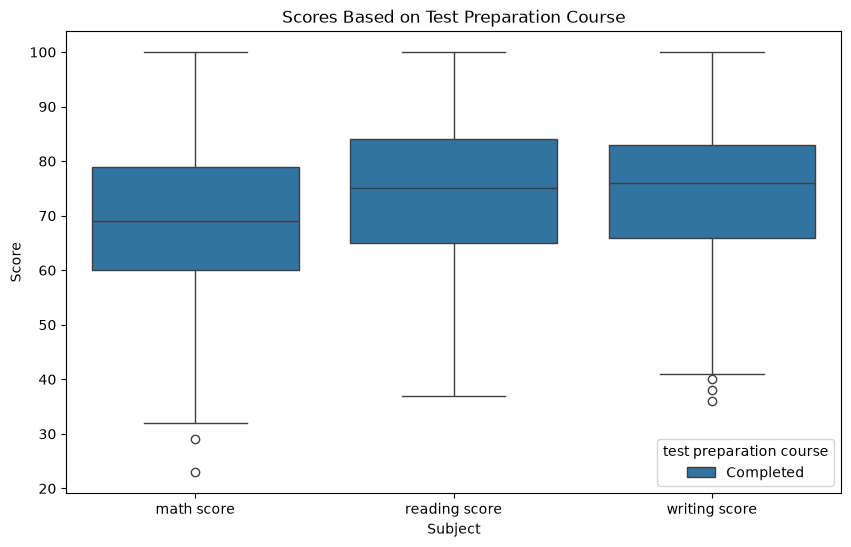

In [13]:
df_melt = df.melt(
    id_vars="test preparation course",
    value_vars=["math score", "reading score", "writing score"],
    var_name="Subject",
    value_name="Score"
)

plt.figure(figsize=(10, 6))

sns.boxplot(data=df_melt, x="Subject", y="Score", hue="test preparation course")

plt.title("Scores Based on Test Preparation Course")
plt.show()

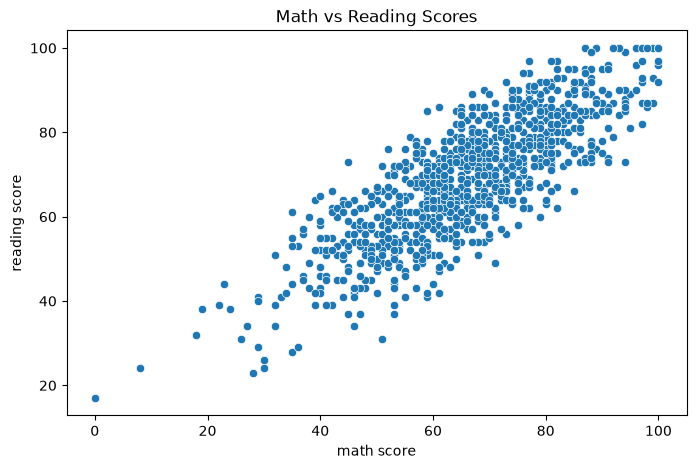

In [14]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="math score", y="reading score")

plt.title("Math vs Reading Scores")
plt.show()

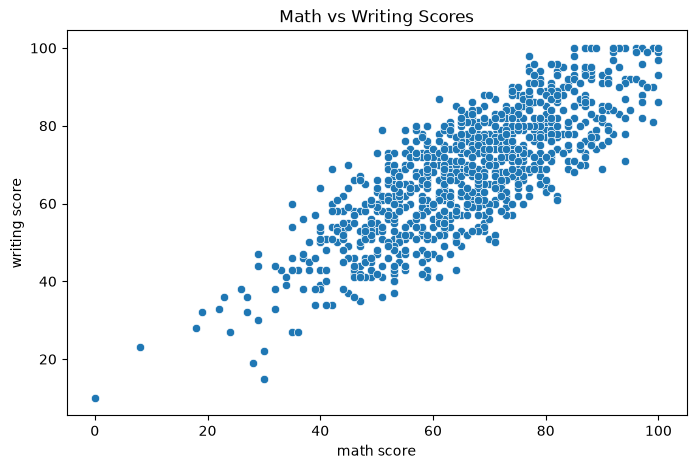

In [15]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="math score", y="writing score")

plt.title("Math vs Writing Scores")
plt.show()

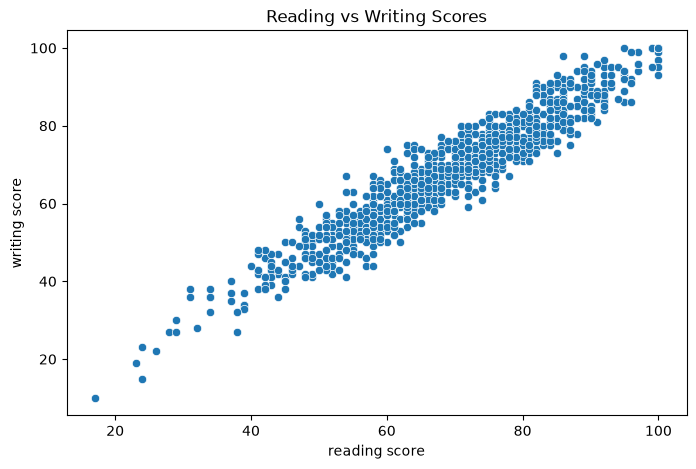

In [16]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="reading score", y="writing score")

plt.title("Reading vs Writing Scores")
plt.show()

In [17]:
corr = df[["math score", "reading score", "writing score"]].corr()

corr

,math score,reading score,writing score
math score,1.000000,0.817580,0.802642
reading score,0.817580,1.000000,0.954598
writing score,0.802642,0.954598,1.000000


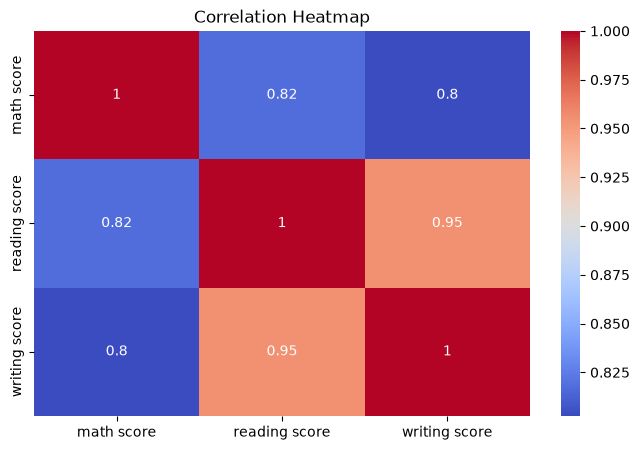

In [18]:
plt.figure(figsize=(8, 5))

sns.heatmap(corr, annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap")
plt.show()

In [19]:
strongest = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()

strongest.idxmax()

('reading score', 'writing score')

In [20]:
strongest.max()

np.float64(0.9545980771462476)

In [21]:
observations = [
    "Highest average score is in " + df[["math score", "reading score", "writing score"]].mean().idxmax(),

    "Lowest average score is in " + df[["math score", "reading score", "writing score"]].mean().idxmin(),

    "Students with standard lunch have an average score of " + str(round(df[df["lunch"] == "standard"][["math score", "reading score", "writing score"]].mean().mean(), 2)),

    "Students with completed test preparation have an average score of " + str(round(df[df["test preparation course"] == "completed"][["math score", "reading score", "writing score"]].mean().mean(), 2)),

    "Strongest correlation is between " + str(strongest.idxmax()[0]) + " and " + str(strongest.idxmax()[1])
]

pd.DataFrame(observations, columns=["Five Observations"])

,Five Observations
0,Highest average score is in reading score
1,Lowest average score is in math score
2,Students with standard lunch have an average s...
3,Students with completed test preparation have ...
4,Strongest correlation is between reading score...


In [22]:
df.to_csv("Student_Performance_Analysis.csv", index=False)